In [18]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
from tqdm.auto import tqdm

# Fixed seeds make the data split and most operations repeatable.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

IMAGE_SIZE = 512
BATCH_SIZE = 2
NUM_WORKERS = 0
LEARNING_RATE = 1e-3
MAX_EPOCHS = 30
PATIENCE = 5
POSITIVE_WEIGHT = 15.0  # Gives rare positive pixels more influence in BCE.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"  # Mixed precision reduces GPU memory use.
print(f"Device: {DEVICE}; mixed precision: {USE_AMP}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda; mixed precision: True
NVIDIA GeForce RTX 3060 Laptop GPU


In [19]:
# Support both this repository layout and common Colab upload locations.
roots = [Path("MuralDH/Mural_seg"), Path("/content/MuralDH/Mural_seg"), Path("/content/Mural_seg")]
DATA_ROOT = next((root for root in roots if root.exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Mural_seg was not found locally or under /content.")

def paired_paths(split):
    """Match each input PNG to a label PNG with the same filename."""
    image_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"
    pairs = [(p, label_dir / p.name) for p in sorted(image_dir.glob("*.png"))]
    missing = [mask for _, mask in pairs if not mask.exists()]
    if missing or not pairs:
        raise RuntimeError(f"Invalid {split} pairs: {len(pairs)} images, {len(missing)} missing masks")
    return pairs

class MuralDataset(Dataset):
    """Load RGB images and binary one-channel pixel masks."""
    def __init__(self, pairs, augment=False):
        self.pairs = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as source:
            image = source.convert("RGB")
        with Image.open(mask_path) as source:
            mask = source.convert("L")

        size = (IMAGE_SIZE, IMAGE_SIZE)
        # Nearest-neighbor preserves mask classes; bilinear is suitable for photos.
        if image.size != size:
            image = image.resize(size, Image.Resampling.BILINEAR)
        if mask.size != size:
            mask = mask.resize(size, Image.Resampling.NEAREST)

        # Image and mask must receive identical geometric augmentation.
        if self.augment and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
        if self.augment and random.random() < 0.5:
            image = image.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
            mask = mask.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

        # Convert HWC uint8 data to PyTorch's CHW float format.
        image = np.asarray(image, dtype=np.float32) / 255.0
        image = torch.from_numpy(image.transpose(2, 0, 1).copy())
        # Explicit thresholding handles the different PNG modes in MuralDH.
        mask = (np.asarray(mask, dtype=np.uint8) > 127).astype(np.float32)
        mask = torch.from_numpy(mask.copy()).unsqueeze(0)
        return image, mask

train_pairs, test_pairs = paired_paths("train"), paired_paths("test")
order = torch.randperm(len(train_pairs), generator=torch.Generator().manual_seed(SEED)).tolist()
validation_count = round(0.15 * len(order))
validation_indices, training_indices = order[:validation_count], order[validation_count:]
train_data = Subset(MuralDataset(train_pairs, augment=True), training_indices)
validation_data = Subset(MuralDataset(train_pairs), validation_indices)
test_data = MuralDataset(test_pairs)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                   pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_data, shuffle=True, **loader_args)
validation_loader = DataLoader(validation_data, shuffle=False, **loader_args)
test_loader = DataLoader(test_data, shuffle=False, **loader_args)
print(f"Train: {len(train_data)}, validation: {len(validation_data)}, test: {len(test_data)}")

Train: 646, validation: 114, test: 201


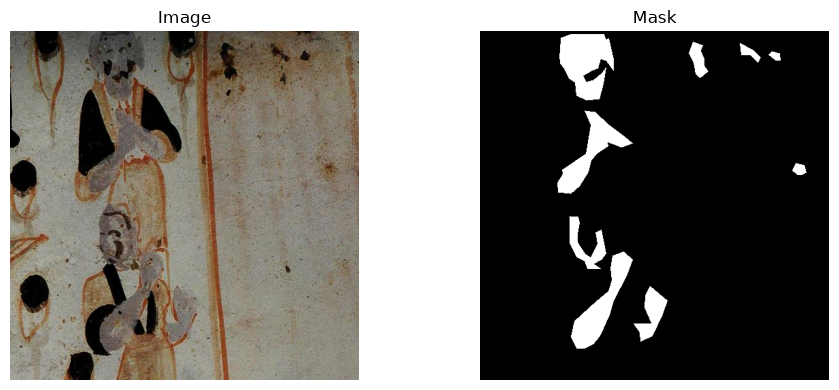

In [20]:
# Inspect a pair before training to catch inverted or misaligned masks.
sample_image, sample_mask = validation_data[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(sample_image.permute(1, 2, 0)); axes[0].set_title("Image")
axes[1].imshow(sample_mask[0], cmap="gray", vmin=0, vmax=1); axes[1].set_title("Mask")
for axis in axes: axis.axis("off")
plt.tight_layout()

## U-Net
The encoder learns increasingly abstract features while pooling reduces resolution. The decoder upsamples them. Skip connections restore fine spatial details needed for precise pixel boundaries.

In [21]:
class DoubleConv(nn.Module):
    """Two convolution-normalization-activation stages."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.layers(x)

class UNet(nn.Module):
    """Compact three-level U-Net producing one logit per image pixel."""
    def __init__(self, channels=32, block=DoubleConv):
        super().__init__()
        c = channels
        self.pool = nn.MaxPool2d(2)
        # Supplying a different block lets us compare activations without
        # changing the U-Net's channel counts, skip connections, or output shape.
        self.enc1, self.enc2 = block(3, c), block(c, 2*c)
        self.enc3, self.bridge = block(2*c, 4*c), block(4*c, 8*c)
        self.up3 = nn.ConvTranspose2d(8*c, 4*c, 2, 2)
        self.dec3 = block(8*c, 4*c)
        self.up2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2)
        self.dec2 = block(4*c, 2*c)
        self.up1 = nn.ConvTranspose2d(2*c, c, 2, 2)
        self.dec1 = block(2*c, c)
        self.output = nn.Conv2d(c, 1, 1)

    def forward(self, x):
        skip1 = self.enc1(x)
        skip2 = self.enc2(self.pool(skip1))
        skip3 = self.enc3(self.pool(skip2))
        x = self.bridge(self.pool(skip3))
        x = self.dec3(torch.cat([self.up3(x), skip3], dim=1))
        x = self.dec2(torch.cat([self.up2(x), skip2], dim=1))
        x = self.dec1(torch.cat([self.up1(x), skip1], dim=1))
        return self.output(x)  # Raw logits; loss applies sigmoid internally.

model = UNet().to(DEVICE)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
with torch.inference_mode():
    output_shape = model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)).shape
print("Output shape:", tuple(output_shape))  # [batch, class, height, width]
if DEVICE.type == "cuda": torch.cuda.empty_cache()

Parameters: 1,927,009
Output shape: (1, 1, 512, 512)


In [22]:
def segmentation_loss(logits, targets):
    """Weighted BCE handles imbalance; Dice directly rewards overlap."""
    weight = logits.new_tensor([POSITIVE_WEIGHT])
    bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=weight)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum((1, 2, 3))
    total = probabilities.sum((1, 2, 3)) + targets.sum((1, 2, 3))
    dice_loss = 1 - ((2 * intersection + 1) / (total + 1)).mean()
    return 0.5 * bce + 0.5 * dice_loss

def run_epoch(loader, optimizer=None, scaler=None, network=None):
    """Train when an optimizer is supplied; otherwise only evaluate."""
    training = optimizer is not None
    network = model if network is None else network
    network.train(training)
    loss_sum = intersection = predicted = actual = 0.0
    for images, targets in tqdm(loader, leave=False):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = network(images)
                loss = segmentation_loss(logits, targets)
            if training:
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        loss_sum += loss.item() * len(images)
        prediction = torch.sigmoid(logits.detach()) >= 0.5
        target = targets >= 0.5
        intersection += (prediction & target).sum().item()
        predicted += prediction.sum().item(); actual += target.sum().item()
    # Aggregate across the dataset so nearly empty masks do not dominate.
    dice = (2 * intersection + 1e-7) / (predicted + actual + 1e-7)
    iou = (intersection + 1e-7) / (predicted + actual - intersection + 1e-7)
    # Derive precision and recall from pixel-level confusion-matrix counts.
    # Precision = TP / (TP + FP); recall = TP / (TP + FN).
    true_positives = intersection
    false_positives = predicted - intersection
    false_negatives = actual - intersection
    precision_denominator = true_positives + false_positives
    recall_denominator = true_positives + false_negatives
    precision = true_positives / precision_denominator if precision_denominator > 0 else 0.0
    recall = true_positives / recall_denominator if recall_denominator > 0 else 0.0
    return {"loss": loss_sum / len(loader.dataset), "dice": dice, "iou": iou,
            "precision": precision, "recall": recall}

In [23]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=2)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
checkpoint_path = Path("best_unet_muraldh.pt")
history = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": [],
           "val_precision": [], "val_recall": []}
best_dice, stale_epochs = -1.0, 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, optimizer, scaler)
    val_metrics = run_epoch(validation_loader)
    scheduler.step(val_metrics["dice"])
    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_dice"].append(val_metrics["dice"])
    history["val_iou"].append(val_metrics["iou"])
    history["val_precision"].append(val_metrics["precision"])
    history["val_recall"].append(val_metrics["recall"])
    print(f"{epoch:02d} | train loss {train_metrics['loss']:.4f} | "
          f"val loss {val_metrics['loss']:.4f} | Dice {val_metrics['dice']:.4f} | "
          f"IoU {val_metrics['iou']:.4f} | Precision {val_metrics['precision']:.4f} | "
          f"Recall {val_metrics['recall']:.4f}")
    if val_metrics["dice"] > best_dice:
        best_dice, stale_epochs = val_metrics["dice"], 0
        # Select checkpoints using validation data, never the test data.
        torch.save({"model": model.state_dict(), "epoch": epoch, "val_dice": best_dice}, checkpoint_path)
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print("Early stopping: validation Dice stopped improving."); break
print(f"Best validation Dice: {best_dice:.4f}")

01 | train loss 0.9628 | val loss 0.9650 | Dice 0.0971 | IoU 0.0510 | Precision 0.0558 | Recall 0.3743


02 | train loss 0.9532 | val loss 0.9692 | Dice 0.0947 | IoU 0.0497 | Precision 0.0521 | Recall 0.5199


03 | train loss 0.9415 | val loss 0.9599 | Dice 0.0465 | IoU 0.0238 | Precision 0.0720 | Recall 0.0343


04 | train loss 0.9402 | val loss 0.9545 | Dice 0.0995 | IoU 0.0523 | Precision 0.0634 | Recall 0.2303


05 | train loss 0.9341 | val loss 0.9669 | Dice 0.1145 | IoU 0.0607 | Precision 0.0904 | Recall 0.1560


06 | train loss 0.9323 | val loss 0.9597 | Dice 0.0888 | IoU 0.0465 | Precision 0.0783 | Recall 0.1026


07 | train loss 0.9357 | val loss 0.9803 | Dice 0.0860 | IoU 0.0449 | Precision 0.0461 | Recall 0.6353


08 | train loss 0.9289 | val loss 0.9807 | Dice 0.1074 | IoU 0.0567 | Precision 0.0748 | Recall 0.1899


09 | train loss 0.9204 | val loss 0.9568 | Dice 0.1141 | IoU 0.0605 | Precision 0.0662 | Recall 0.4121


10 | train loss 0.9197 | val loss 0.9613 | Dice 0.1077 | IoU 0.0569 | Precision 0.0601 | Recall 0.5212
Early stopping: validation Dice stopped improving.
Best validation Dice: 0.1145


Test Dice: 0.0890; Test IoU: 0.0466; Test precision: 0.0871; Test recall: 0.0909


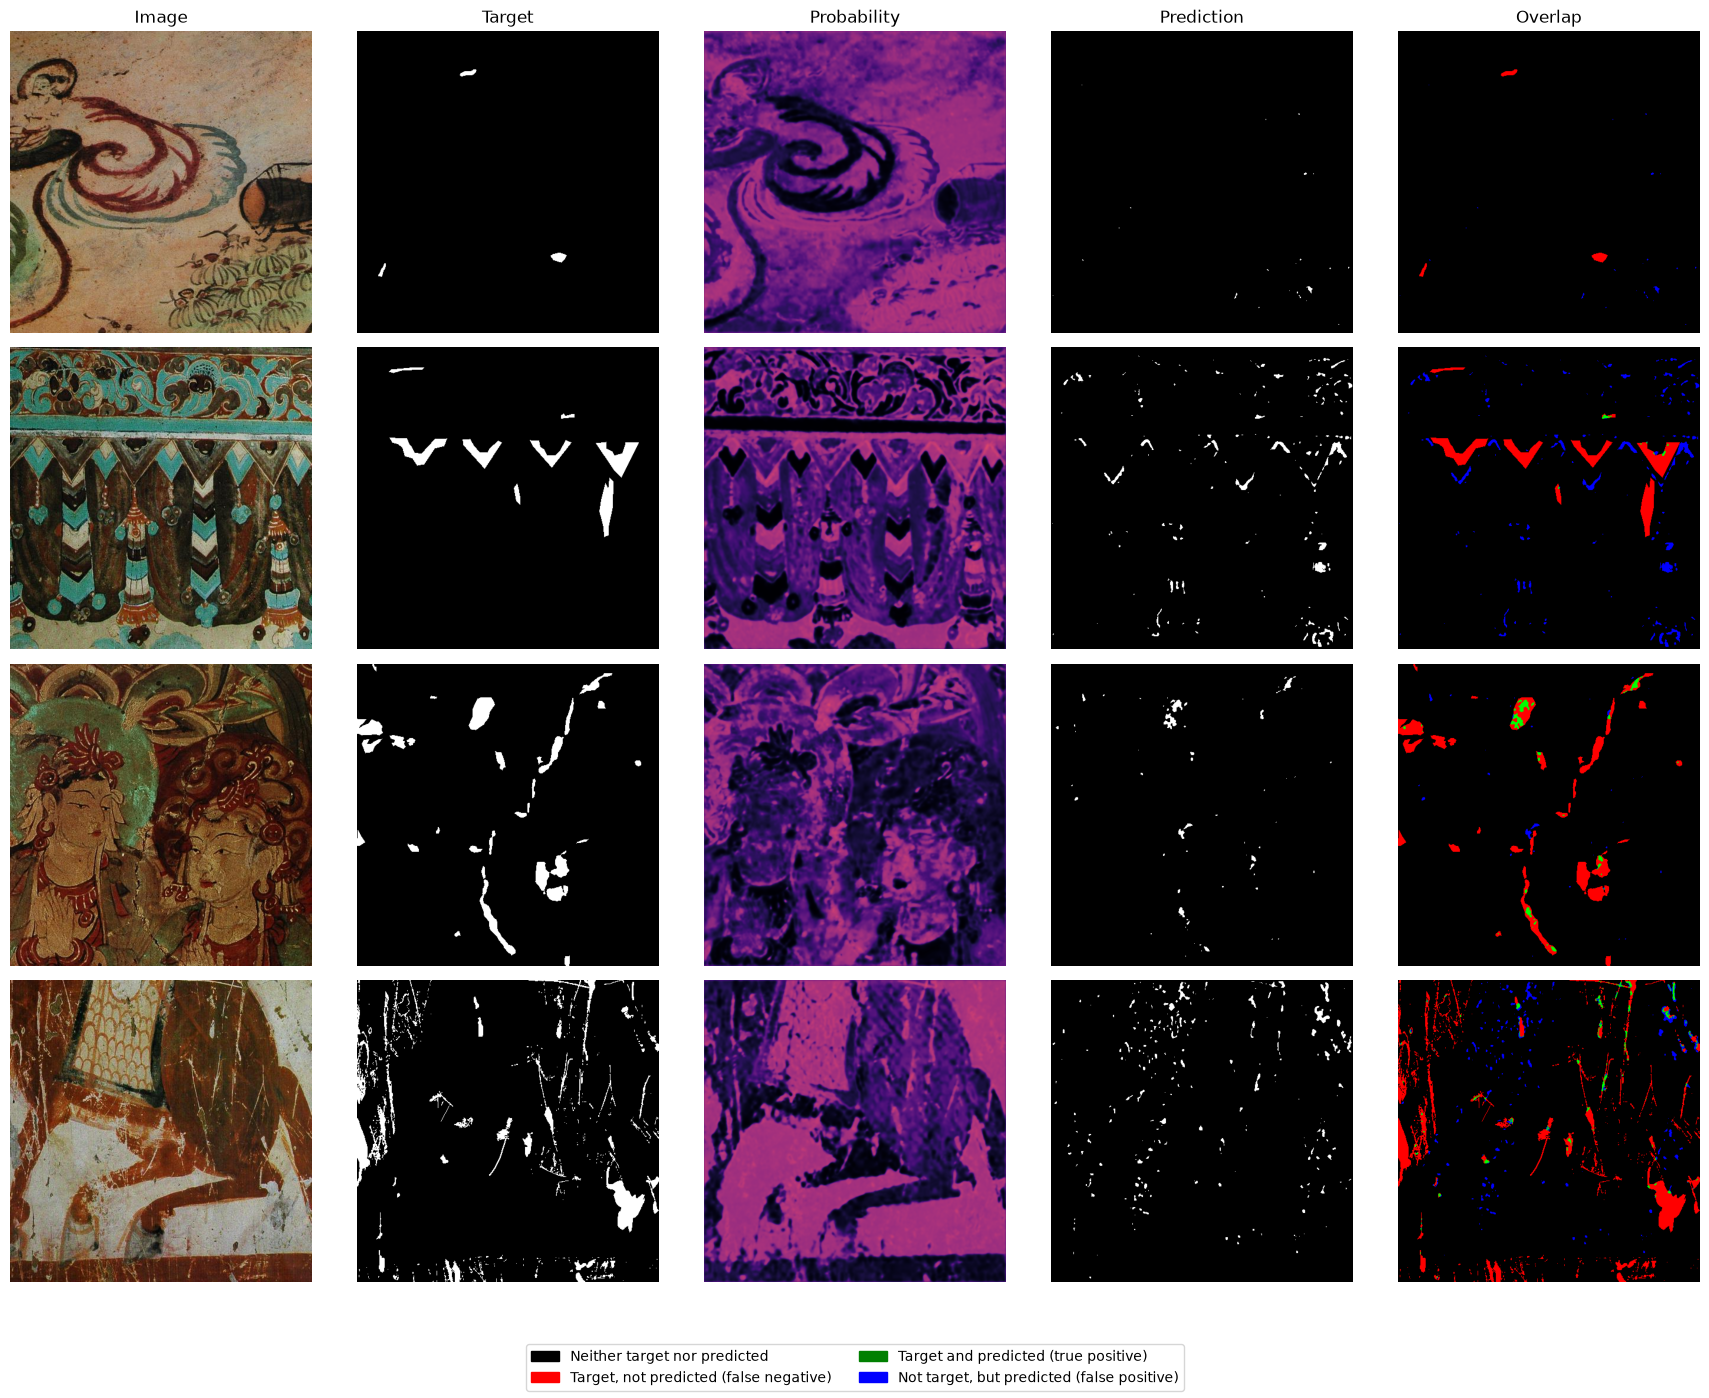

In [24]:
# Evaluate the held-out test set once, using the best validation checkpoint.
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model"])
test_metrics = run_epoch(test_loader)
print(
    f"Test Dice: {test_metrics['dice']:.4f}; "
    f"Test IoU: {test_metrics['iou']:.4f}; "
    f"Test precision: {test_metrics['precision']:.4f}; "
    f"Test recall: {test_metrics['recall']:.4f}"
)

def show_predictions(count=4, threshold=0.5, network=None):
    """Compare true masks, soft probabilities, and binary predictions."""
    from matplotlib.patches import Patch

    network = model if network is None else network
    network.eval()
    indices = np.linspace(0, len(test_data) - 1, count, dtype=int)
    fig, axes = plt.subplots(count, 5, figsize=(17.5, 3.5 * count), squeeze=False)
    with torch.inference_mode():
        for row, index in enumerate(indices):
            image, target = test_data[index]
            probability = torch.sigmoid(network(image[None].to(DEVICE)))[0, 0].cpu()
            prediction = probability >= threshold
            target_mask = target[0].bool()

            # RGB overlap colors: black=true negative, red=false negative,
            # green=true positive, and blue=false positive.
            overlap = torch.zeros((*target_mask.shape, 3), dtype=torch.float32)
            overlap[target_mask & ~prediction] = torch.tensor([1.0, 0.0, 0.0])
            overlap[target_mask & prediction] = torch.tensor([0.0, 1.0, 0.0])
            overlap[~target_mask & prediction] = torch.tensor([0.0, 0.0, 1.0])
            axes[row, 0].imshow(image.permute(1, 2, 0))
            axes[row, 1].imshow(target[0], cmap="gray", vmin=0, vmax=1)
            axes[row, 2].imshow(probability, cmap="magma", vmin=0, vmax=1)
            axes[row, 3].imshow(prediction, cmap="gray", vmin=0, vmax=1)
            axes[row, 4].imshow(overlap)
    for col, title in enumerate(["Image", "Target", "Probability", "Prediction", "Overlap"]):
        axes[0, col].set_title(title)
    for axis in axes.flat: axis.axis("off")
    overlap_legend = [
        Patch(color="black", label="Neither target nor predicted"),
        Patch(color="red", label="Target, not predicted (false negative)"),
        Patch(color="green", label="Target and predicted (true positive)"),
        Patch(color="blue", label="Not target, but predicted (false positive)"),
    ]
    fig.legend(handles=overlap_legend, loc="lower center", ncol=2)
    plt.tight_layout(rect=(0, 0.07, 1, 1))

show_predictions()

## Tanh U-Net comparison

This experiment keeps the same U-Net shape, channel counts, normalization layers, skip connections, and one-channel logit output. Only the hidden-layer activation changes from ReLU to `Tanh`. The final layer remains linear because `BCEWithLogitsLoss` expects raw logits.

In [25]:
class TanhDoubleConv(nn.Module):
    """The same double-convolution block, using Tanh instead of ReLU."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.Tanh(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.Tanh(),
        )

    def forward(self, x):
        return self.layers(x)


# UNet supplies all pooling, upsampling, skip connections, and output logic.
# Passing TanhDoubleConv changes only the hidden activation function.
tanh_model = UNet(channels=32, block=TanhDoubleConv).to(DEVICE)
relu_parameters = sum(parameter.numel() for parameter in model.parameters())
tanh_parameters = sum(parameter.numel() for parameter in tanh_model.parameters())

with torch.inference_mode():
    tanh_output_shape = tanh_model(
        torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    ).shape

print(f"ReLU parameters: {relu_parameters:,}")
print(f"Tanh parameters: {tanh_parameters:,}")
print("Tanh output shape:", tuple(tanh_output_shape))
assert tanh_parameters == relu_parameters
assert tuple(tanh_output_shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

ReLU parameters: 1,927,009
Tanh parameters: 1,927,009
Tanh output shape: (1, 1, 512, 512)


In [26]:
def train_model_variant(network, checkpoint_file):
    """Train a model with the same settings used for the ReLU baseline."""
    variant_optimizer = torch.optim.AdamW(
        network.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    variant_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        variant_optimizer, mode="max", patience=2
    )
    variant_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    variant_history = {
        "train_loss": [], "val_loss": [], "val_dice": [],
        "val_iou": [], "val_precision": [], "val_recall": [],
    }
    best_variant_dice, stale_epochs = -1.0, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_result = run_epoch(
            train_loader, variant_optimizer, variant_scaler, network=network
        )
        val_result = run_epoch(validation_loader, network=network)
        variant_scheduler.step(val_result["dice"])

        variant_history["train_loss"].append(train_result["loss"])
        variant_history["val_loss"].append(val_result["loss"])
        for metric in ("dice", "iou", "precision", "recall"):
            variant_history[f"val_{metric}"].append(val_result[metric])

        print(
            f"{epoch:02d} | train loss {train_result['loss']:.4f} | "
            f"val loss {val_result['loss']:.4f} | Dice {val_result['dice']:.4f} | "
            f"IoU {val_result['iou']:.4f} | Precision {val_result['precision']:.4f} | "
            f"Recall {val_result['recall']:.4f}"
        )

        if val_result["dice"] > best_variant_dice:
            best_variant_dice, stale_epochs = val_result["dice"], 0
            torch.save(
                {"model": network.state_dict(), "epoch": epoch,
                 "val_dice": best_variant_dice, "activation": "tanh"},
                checkpoint_file,
            )
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                print("Early stopping: validation Dice stopped improving.")
                break

    print(f"Best Tanh validation Dice: {best_variant_dice:.4f}")
    return variant_history


tanh_checkpoint_path = Path("best_tanh_unet_muraldh.pt")
tanh_history = train_model_variant(tanh_model, tanh_checkpoint_path)

01 | train loss 0.9927 | val loss 0.9673 | Dice 0.0922 | IoU 0.0483 | Precision 0.0579 | Recall 0.2258


02 | train loss 0.9751 | val loss 0.9745 | Dice 0.0836 | IoU 0.0436 | Precision 0.0460 | Recall 0.4595


03 | train loss 0.9681 | val loss 0.9680 | Dice 0.0044 | IoU 0.0022 | Precision 0.1870 | Recall 0.0022


04 | train loss 0.9659 | val loss 0.9661 | Dice 0.0874 | IoU 0.0457 | Precision 0.0506 | Recall 0.3193


05 | train loss 0.9559 | val loss 0.9659 | Dice 0.0941 | IoU 0.0494 | Precision 0.0545 | Recall 0.3417


06 | train loss 0.9516 | val loss 0.9622 | Dice 0.0936 | IoU 0.0491 | Precision 0.0566 | Recall 0.2687


... (10 outputs left out)

17 | train loss 0.9263 | val loss 0.9519 | Dice 0.0993 | IoU 0.0522 | Precision 0.0577 | Recall 0.3530


18 | train loss 0.9284 | val loss 0.9515 | Dice 0.1037 | IoU 0.0547 | Precision 0.0605 | Recall 0.3651


19 | train loss 0.9260 | val loss 0.9510 | Dice 0.1048 | IoU 0.0553 | Precision 0.0616 | Recall 0.3503


20 | train loss 0.9332 | val loss 0.9513 | Dice 0.1030 | IoU 0.0543 | Precision 0.0610 | Recall 0.3308
Early stopping: validation Dice stopped improving.
Best Tanh validation Dice: 0.1087


Tanh test Dice: 0.1415; IoU: 0.0761; precision: 0.0923; recall: 0.3025


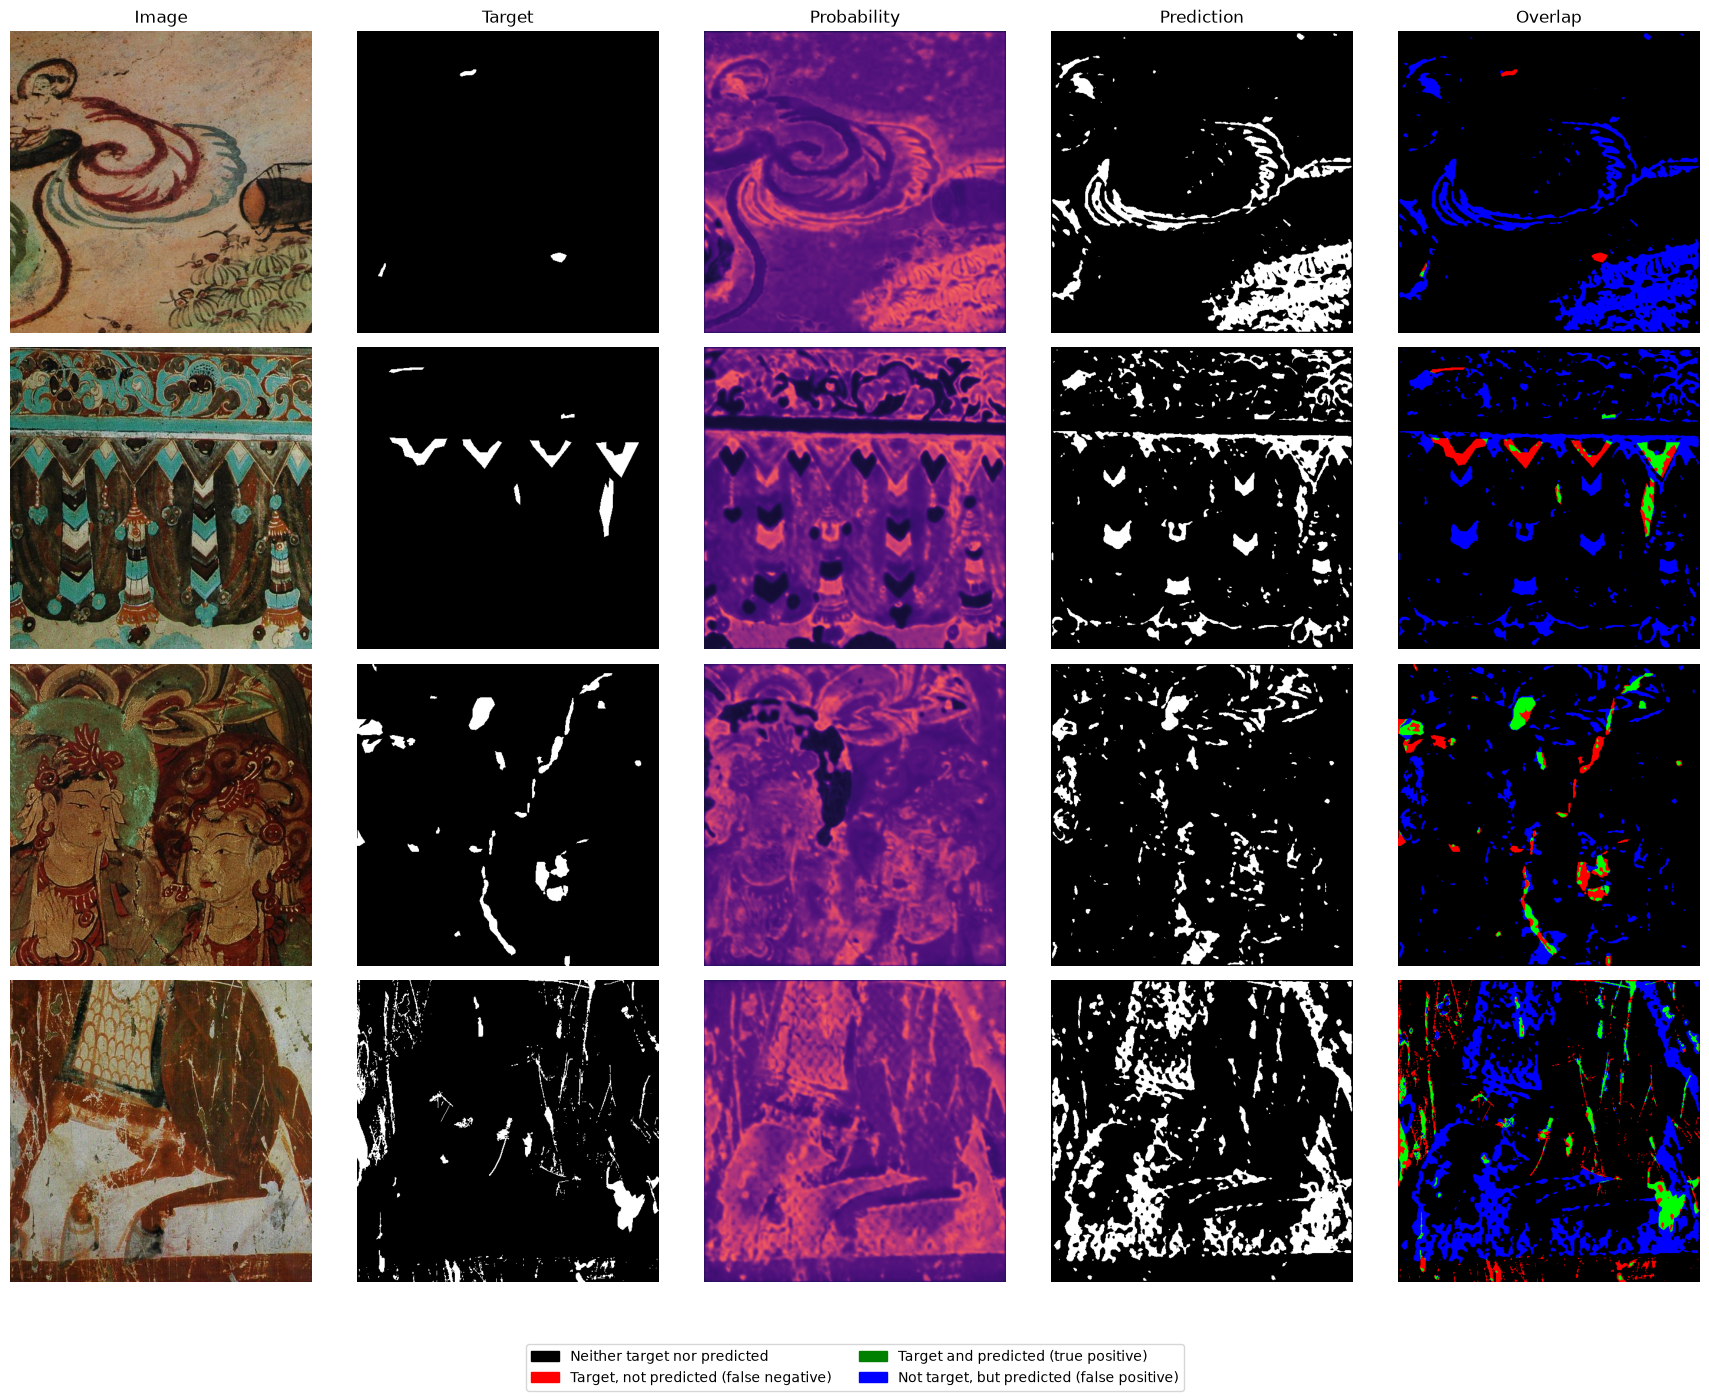

In [27]:
# Load the best Tanh checkpoint before measuring the untouched test set.
tanh_checkpoint = torch.load(
    tanh_checkpoint_path, map_location=DEVICE, weights_only=False
)
tanh_model.load_state_dict(tanh_checkpoint["model"])
tanh_test_metrics = run_epoch(test_loader, network=tanh_model)
print(
    f"Tanh test Dice: {tanh_test_metrics['dice']:.4f}; "
    f"IoU: {tanh_test_metrics['iou']:.4f}; "
    f"precision: {tanh_test_metrics['precision']:.4f}; "
    f"recall: {tanh_test_metrics['recall']:.4f}"
)

# Reuse the five-column display, including the colored overlap mask.
show_predictions(network=tanh_model)

## Smaller U-Net: grokking-style experiment

Grokking means that a model memorizes its training data first and only generalizes much later. It is most reproducible on small algorithmic datasets, so it is **not guaranteed** on mural segmentation. This experiment creates conditions that make it observable if it occurs: a fixed finite training set, a smaller model, stronger weight decay, constant learning rate, and long training with no early stopping.

In [6]:
# This model is slightly narrower than the 32-channel baselines. Because U-Net
# parameter count scales roughly with channel width squared, 28 channels makes
# a modest size reduction without changing the input or output resolution.
GROK_CHANNELS = 24
GROK_EPOCHS = 25000
GROK_LEARNING_RATE = 3e-4
GROK_WEIGHT_DECAY = 1e-2
GROK_LOG_EVERY = 25
GROK_RESUME = True

grok_model = UNet(channels=GROK_CHANNELS, block=DoubleConv).to(DEVICE)
grok_parameters = sum(parameter.numel() for parameter in grok_model.parameters())
baseline_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"Baseline parameters: {baseline_parameters:,}")
print(f"Smaller model parameters: {grok_parameters:,} "
      f"({grok_parameters / baseline_parameters:.1%} of baseline)")

# Do not augment these examples. Grokking is defined relative to memorizing a
# fixed finite training set; continually changing augmentation obscures that point.
grok_train_data = Subset(MuralDataset(train_pairs, augment=False), training_indices)
grok_train_loader = DataLoader(grok_train_data, shuffle=True, **loader_args)

with torch.inference_mode():
    grok_output_shape = grok_model(
        torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    ).shape
print("Smaller model output shape:", tuple(grok_output_shape))
assert tuple(grok_output_shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Baseline parameters: 1,927,009
Smaller model parameters: 1,084,681 (56.3% of baseline)
Smaller model output shape: (1, 1, 512, 512)


In [7]:
grok_best_path = Path("best_grok_unet_muraldh.pt")
grok_latest_path = Path("latest_grok_unet_muraldh.pt")
grok_optimizer = torch.optim.AdamW(
    grok_model.parameters(), lr=GROK_LEARNING_RATE, weight_decay=GROK_WEIGHT_DECAY
)
grok_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
grok_history = {
    "train_loss": [], "train_dice": [], "train_iou": [],
    "val_loss": [], "val_dice": [], "val_iou": [],
    "val_precision": [], "val_recall": [],
}
start_epoch, best_grok_dice = 1, -1.0

# Long runs can be interrupted. The latest checkpoint contains optimizer and
# history state so rerunning this cell can continue rather than start over.
if GROK_RESUME and grok_latest_path.exists():
    saved = torch.load(grok_latest_path, map_location=DEVICE, weights_only=False)
    grok_model.load_state_dict(saved["model"])
    grok_optimizer.load_state_dict(saved["optimizer"])
    grok_scaler.load_state_dict(saved["scaler"])
    grok_history = saved["history"]
    best_grok_dice = saved["best_val_dice"]
    start_epoch = saved["epoch"] + 1
    print(f"Resuming after epoch {saved['epoch']}")

for epoch in range(start_epoch, GROK_EPOCHS + 1):
    train_result = run_epoch(
        grok_train_loader, grok_optimizer, grok_scaler, network=grok_model
    )
    val_result = run_epoch(validation_loader, network=grok_model)

    for metric in ("loss", "dice", "iou"):
        grok_history[f"train_{metric}"].append(train_result[metric])
        grok_history[f"val_{metric}"].append(val_result[metric])
    grok_history["val_precision"].append(val_result["precision"])
    grok_history["val_recall"].append(val_result["recall"])

    if epoch == 1 or epoch % GROK_LOG_EVERY == 0:
        print(
            f"{epoch:03d} | train loss {train_result['loss']:.4f}, "
            f"Dice {train_result['dice']:.4f} | val loss {val_result['loss']:.4f}, "
            f"Dice {val_result['dice']:.4f}, IoU {val_result['iou']:.4f}"
        )

    # Keep the best-generalizing model, but deliberately continue training.
    # Stopping at the first plateau would prevent delayed generalization.
    if val_result["dice"] > best_grok_dice:
        best_grok_dice = val_result["dice"]
        torch.save(
            {"model": grok_model.state_dict(), "epoch": epoch,
             "val_dice": best_grok_dice, "channels": GROK_CHANNELS},
            grok_best_path,
        )

    torch.save(
        {"model": grok_model.state_dict(), "optimizer": grok_optimizer.state_dict(),
         "scaler": grok_scaler.state_dict(), "history": grok_history,
         "epoch": epoch, "best_val_dice": best_grok_dice},
        grok_latest_path,
    )

print(f"Best grokking-experiment validation Dice: {best_grok_dice:.4f}")

Resuming after epoch 331


350 | train loss 0.1513, Dice 0.8891 | val loss 2.9222, Dice 0.0993, IoU 0.0523


375 | train loss 0.1519, Dice 0.8877 | val loss 3.0541, Dice 0.1185, IoU 0.0630


400 | train loss 0.1409, Dice 0.8941 | val loss 3.0834, Dice 0.1275, IoU 0.0681


425 | train loss 0.1350, Dice 0.8979 | val loss 3.9152, Dice 0.0861, IoU 0.0450


450 | train loss 0.1240, Dice 0.9048 | val loss 3.5207, Dice 0.1094, IoU 0.0579


... (50 outputs left out)

1725 | train loss 0.0616, Dice 0.9434 | val loss 4.6075, Dice 0.0702, IoU 0.0364


1750 | train loss 0.0772, Dice 0.9303 | val loss 4.4655, Dice 0.0510, IoU 0.0262


1775 | train loss 0.0349, Dice 0.9611 | val loss 4.7303, Dice 0.0668, IoU 0.0346


KeyboardInterrupt: 

Small grok-style test Dice: 0.2144; IoU: 0.1201; precision: 0.2083; recall: 0.2208


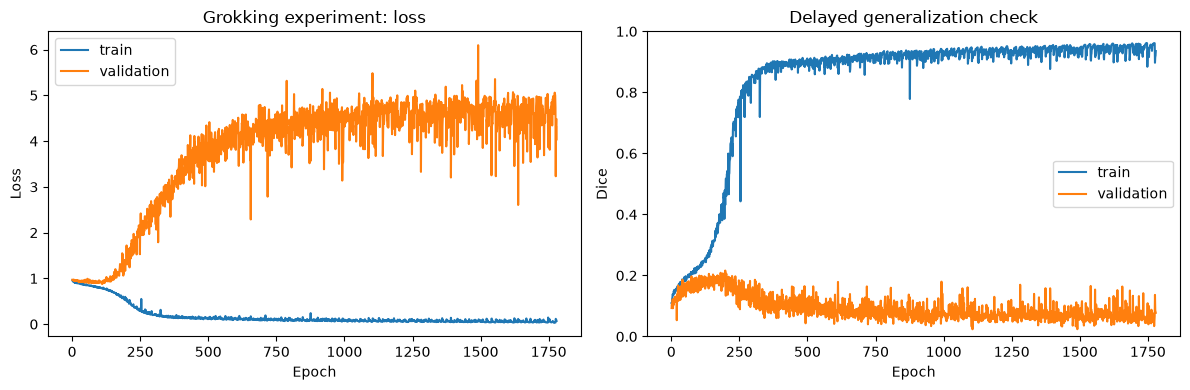

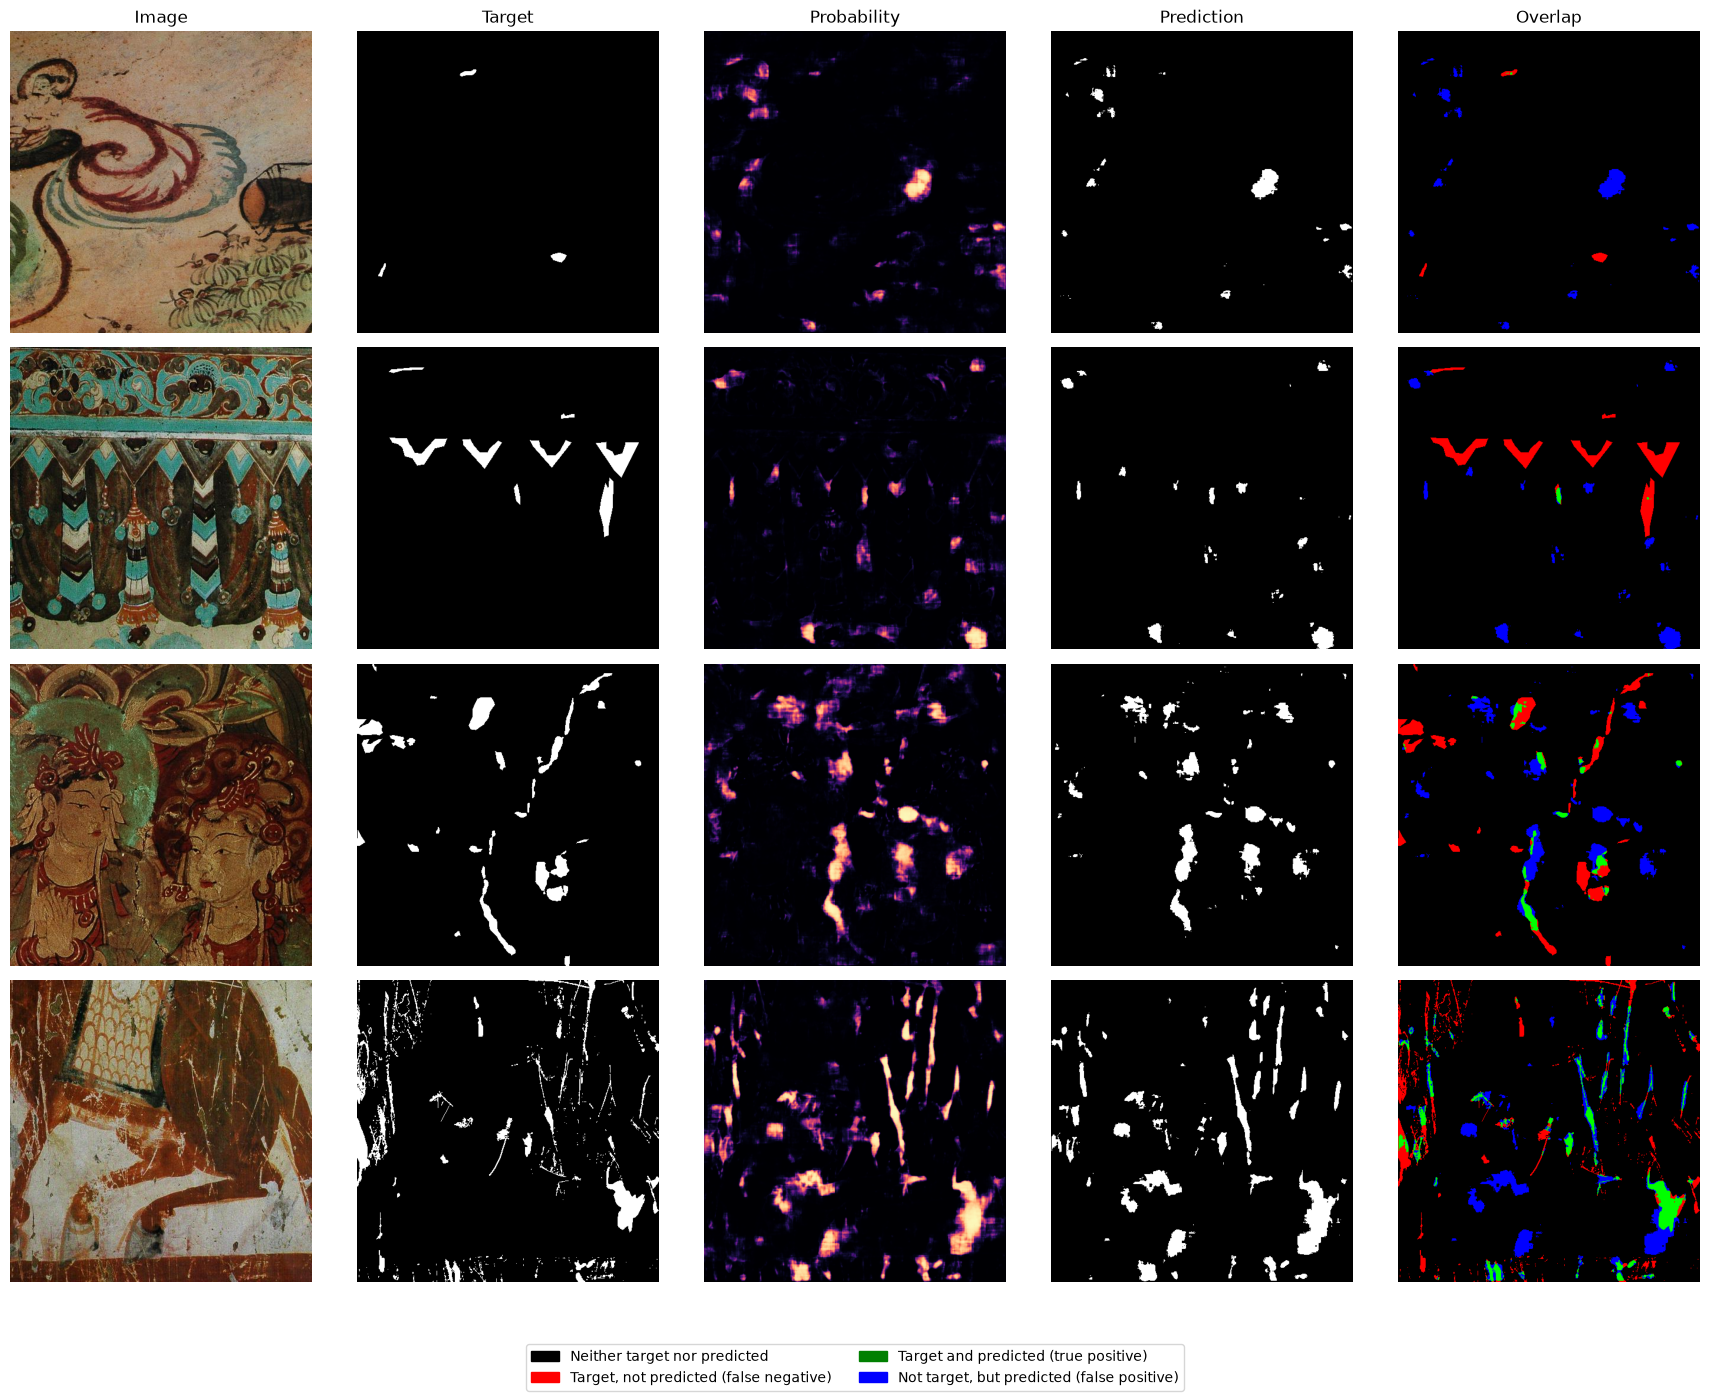

In [28]:
# Grokking appears as an early train/validation gap followed by a delayed rise
# in validation Dice. Plot both curves rather than looking only at the best score.
grok_epochs = range(1, len(grok_history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(grok_epochs, grok_history["train_loss"], label="train")
axes[0].plot(grok_epochs, grok_history["val_loss"], label="validation")
axes[0].set(title="Grokking experiment: loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(grok_epochs, grok_history["train_dice"], label="train")
axes[1].plot(grok_epochs, grok_history["val_dice"], label="validation")
axes[1].set(title="Delayed generalization check", xlabel="Epoch",
            ylabel="Dice", ylim=(0, 1))
axes[1].legend()
plt.tight_layout()

# Report the best checkpoint, not merely the final long-training checkpoint.
grok_best = torch.load(grok_best_path, map_location=DEVICE, weights_only=False)
grok_model.load_state_dict(grok_best["model"])
grok_test_metrics = run_epoch(test_loader, network=grok_model)
print(
    f"Small grok-style test Dice: {grok_test_metrics['dice']:.4f}; "
    f"IoU: {grok_test_metrics['iou']:.4f}; "
    f"precision: {grok_test_metrics['precision']:.4f}; "
    f"recall: {grok_test_metrics['recall']:.4f}"
)
show_predictions(network=grok_model)